# Task 1:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load cameraman image and resize for faster FFT
image = data.camera()
image = resize(image, (256, 256))

# Get image size
M, N = image.shape


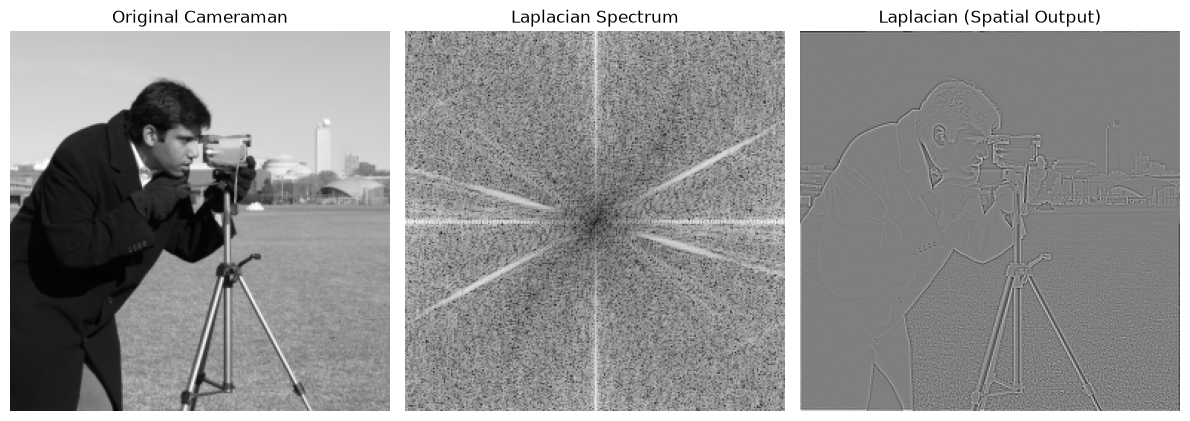

In [2]:
# Generate the frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute the Laplacian filter in the frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply the 2D FFT and the frequency domain filter
F = np.fft.fft2(image)
F_lap = F * laplacian_filter

# Inverse FFT to obtain the spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Display the original image, filtered spectrum, and spatial output
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
ax[0].imshow(image, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original Cameraman")
ax[0].axis("off")

laplacian_spectrum = np.log1p(np.abs(np.fft.fftshift(F_lap)))
ax[1].imshow(laplacian_spectrum, cmap="gray")
ax[1].set_title("Laplacian Spectrum")
ax[1].axis("off")

display_limit = np.max(np.abs(laplacian_image))
ax[2].imshow(laplacian_image, cmap="gray", vmin=-display_limit, vmax=display_limit)
ax[2].set_title("Laplacian (Spatial Output)")
ax[2].axis("off")

plt.tight_layout()
plt.show()

# Assessment Task 1:

In [3]:
# Sobel filters from the lab manual
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Center a spatial filter in the image-sized frequency grid
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape

    # Find center coordinates
    cy, cx = ph // 2, pw // 2

    # Insert the kernel at the center, then shift it to the origin
    padded[cy - kh // 2:cy - kh // 2 + kh,
           cx - kw // 2:cx - kw // 2 + kw] = kernel

    return np.fft.fft2(np.fft.ifftshift(padded))

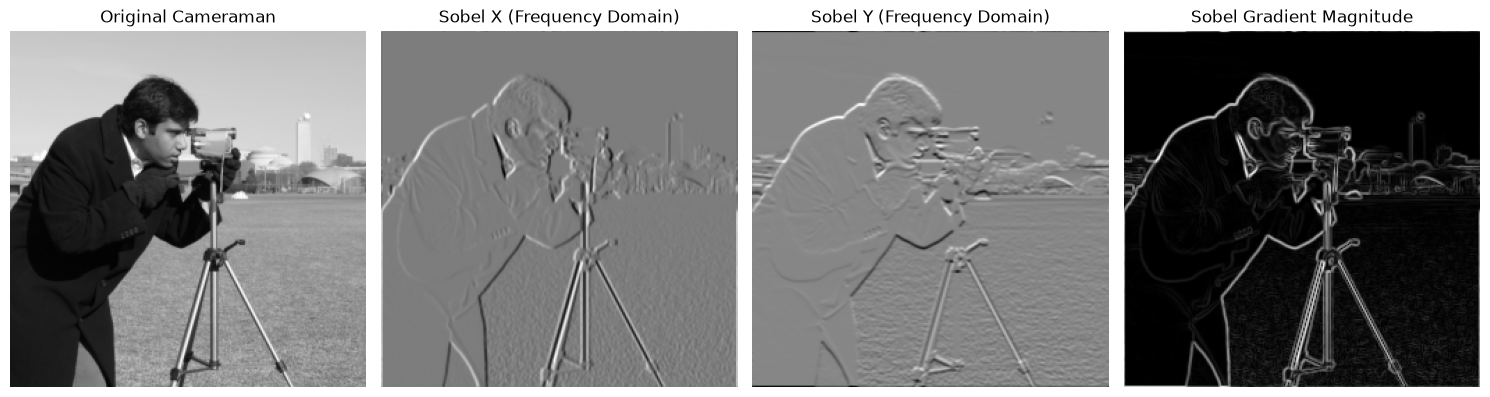

In [4]:
# Compute the FFT of the image and centered Sobel filters
F = np.fft.fft2(image)
sobel_x_frequency = center_embed_kernel(sobel_x, image.shape)
sobel_y_frequency = center_embed_kernel(sobel_y, image.shape)

# Apply both Sobel filters in the frequency domain
sobel_x_image = np.fft.ifft2(F * sobel_x_frequency).real
sobel_y_image = np.fft.ifft2(F * sobel_y_frequency).real
sobel_magnitude = np.hypot(sobel_x_image, sobel_y_image)

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(image, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original Cameraman")
ax[0].axis("off")

ax[1].imshow(sobel_x_image, cmap="gray")
ax[1].set_title("Sobel X (Frequency Domain)")
ax[1].axis("off")

ax[2].imshow(sobel_y_image, cmap="gray")
ax[2].set_title("Sobel Y (Frequency Domain)")
ax[2].axis("off")

ax[3].imshow(sobel_magnitude, cmap="gray")
ax[3].set_title("Sobel Gradient Magnitude")
ax[3].axis("off")

plt.tight_layout()
plt.show()